### Special thanks to Ian Crossfield for this problem.

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import smplotlib
from scipy.integrate import cumulative_trapezoid
from astropy import units as u, constants as const

data = pd.read_csv("./data_sets/saturn_interior_nettelmann2013.csv")

Rsat = 58232*u.km
Msat = 5.68317e26*u.kg
gsat = 10.44 *(u.m/u.s**2)

## Part a) Plot Saturn’s density profile $\rho(r)$ (from the data file). Explain why you think the density profile has the general shape that it does (don’t worry about explaining every little wiggle, but focus on the larger overall features). 1pt

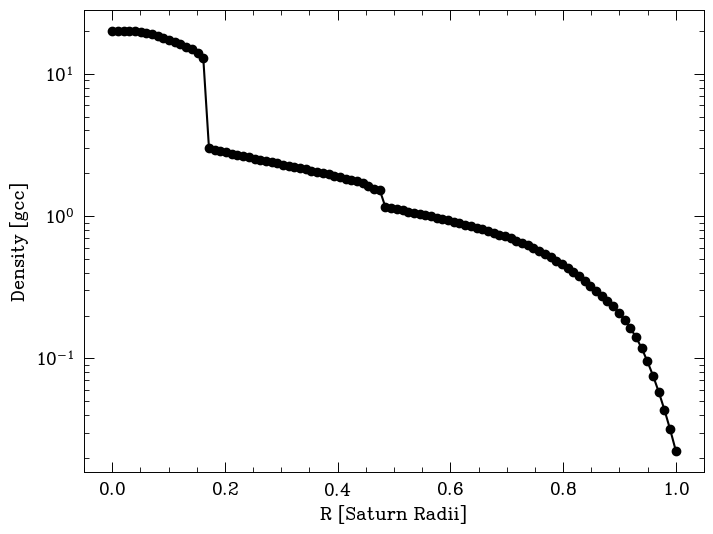

In [2]:
fig, ax = plt.subplots(figsize=(8,6))

ax.plot(data.r,data.rho_cgs,marker='o',c='k')
ax.set_xlabel("R [Saturn Radii]")
ax.set_ylabel("Density [gcc]")
ax.set_yscale('log')

### The density of profile of Saturn shows a gradual increase in density from 1.0 R$_{Saturn}$ to about 0.5 R$_{Saturn}$ where we see a slight jump in density indicating a transition to a higher density layer of the atmosphere (possibly from gaseous hydrogen to a metallic liquid) . More importantly we see a steep jump in density starting at 0.2 R$_{Saturn}$ potentially indicating the start of a rocky core. 

## Part b) Calculate and plot Saturn’s enclosed mass, Menc, from 0 < r < $R_{Sat}$ . Describe and try to explain the general, overall features shown in your plot. 1pt

In [51]:
r_int = data.r.to_numpy() * Rsat.to(u.cm)

menc = data.rho_cgs.to_numpy() * (4 * np.pi * r_int**2)

mass = cumulative_trapezoid(menc,r_int.value,initial=0)

Text(0, 0.5, 'Mass Enclosed [kg]')

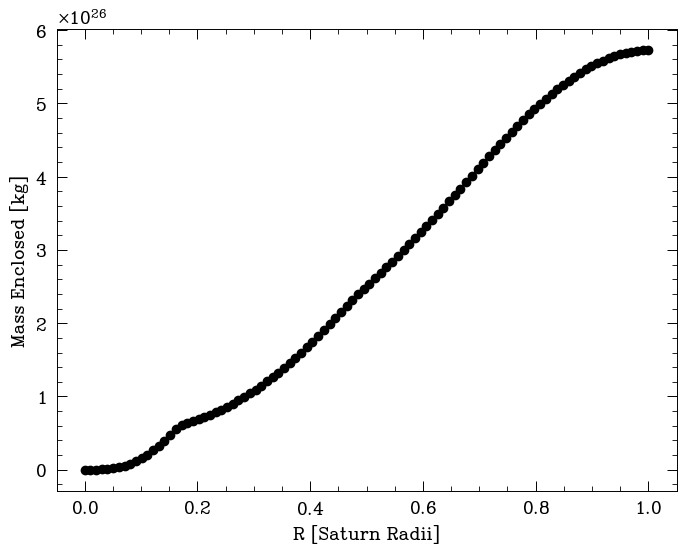

In [52]:
fig, ax = plt.subplots(figsize=(8,6))

ax.plot(data.r,mass/1000,marker='o',c='k')
ax.set_xlabel("R [Saturn Radii]")
ax.set_ylabel("Mass Enclosed [kg]")
#ax.set_yscale('log')

## Part c) What do you calculate for $M_{enc}(r=R_{Sat})$, i.e. for the total mass of Saturn? Explain how well your answer compares to the true, measured mass of Saturn. 1pt

In [30]:
mass[-1]/1000

5.7333369460550355e+26

### The total enclosed mass is close to the true mass of Saturn, 5.68e26

# Second Part, from Problem Set 5

## Part a) Calculate and plot Saturn’s internal gravity field, g(r), for 0 < r < $R_{Sat}$ . Describe and try to explain the general, overall features shown in your plot.

Text(0, 0.5, 'Surface Gravity [m s$^{-2}$]')

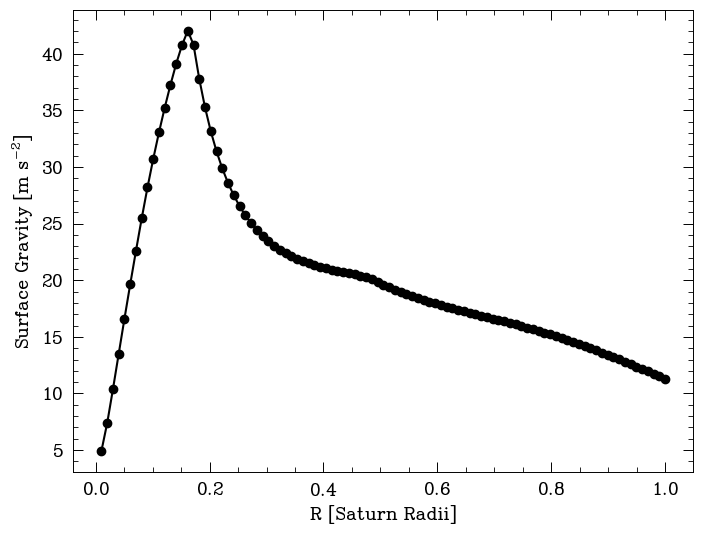

In [53]:
# Surface gravity is simply G * Menc / r^2

grav = (const.G * (mass/1000))/(data.r.to_numpy() * Rsat.to(u.m))**2


fig, ax = plt.subplots(figsize=(8,6))

ax.plot(data.r,grav,marker='o',c='k')
ax.set_xlabel("R [Saturn Radii]")
ax.set_ylabel(r"Surface Gravity [m s$^{-2}$]")

### The gravity field initially increases steeply since we are passing through the region of Saturn with the highest density (i.e the rocky/icey core). This is also a region where the _volume_ is increasing slowly since we are at small r. 

### As we leave the inner core, we reach the region of metallic hydrogen, which is comparatively less dense than the core (by almost an order of magnitude!). This results in 1/r$^{2}$ behavior of the gravity field since we are not adding as much mass anymore as our volume increases.

### Finally, as we reach the outer H/He atmosphere of Saturn, the gravity field flattens. Even though the density of material now being added as we go out in radius is less dense still, the r$^{3}$ dependence on volume really kicks in, meaning the rate of additional mass being added is _higher_ than before.

## Part b) Calculate and plot Saturn’s internal pressure, P(r), for 0 < r < $R_{Sat}$ . Give the central pressure, P$_{c}$, for this model and describe how it compares to the central pressure you calculated rom the simple order-of- magnitude estimate of $g_{surf}$ $\rho$ $R_{Sat}$

Text(0, 0.5, 'Pressure [Pa]')

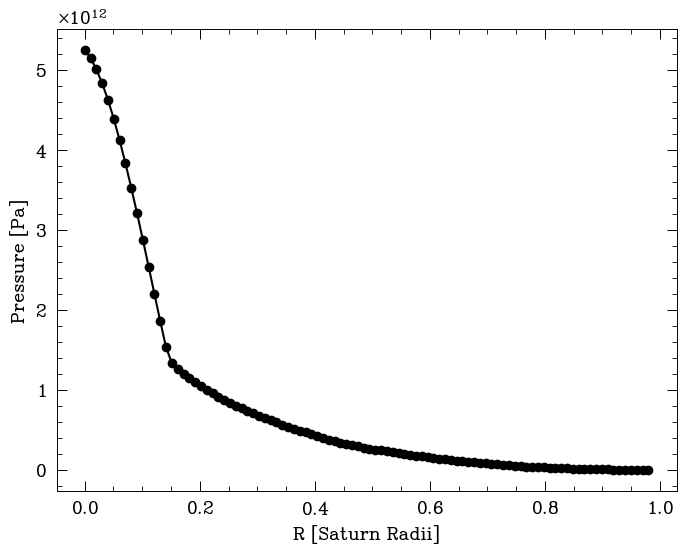

In [94]:
# We know that dP/dr = - rho*g

dP = -data.rho_cgs*1000.0 * grav

r_int = data.r[1:].to_numpy() * Rsat.to(u.m).value

press = cumulative_trapezoid(dP[1:],r_int)
press = press-press[-1] 

fig, ax = plt.subplots(figsize=(8,6))

ax.plot(data.r[:-2],press,marker='o',c='k')
ax.set_xlabel("R [Saturn Radii]")
ax.set_ylabel(r"Pressure [Pa]")

In [82]:
pressure_estimate = gsat * (Msat / ((4/3)*np.pi*Rsat.to(u.m)**3)) * Rsat.to(u.m)

print(rf'Calculated Central Pressure: {press[0] / 1e12} 10^12')
print(rf'Estimated Central Pressure: {pressure_estimate.value / 1e12} 10^12')


Calculated Central Pressure: 5.249940223377854 10^12
Estimated Central Pressure: 0.41771408910573377 10^12


## Somewhat close to the true central pressure

## Part c) Recall that in an adiabatic environment, $P\propto\rho^{\gamma}$. Compare your pressure plot to one for this scaling relation (assuming $\gamma=7/5$), what might you conclude from this comparison about the interior structure of Saturn and the processes occurring inside different regions? (Hint: Plot P(r) and $\rho(r)^\gamma$ and normalize each curve by their largest values to better compare them).

Text(0, 0.5, 'Pressure')

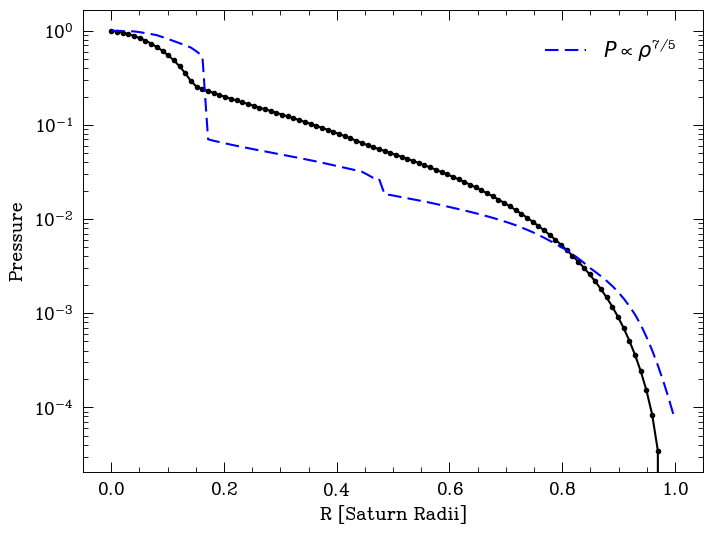

In [97]:
rho_gamma = data.rho_cgs**(7/5)

fig, ax = plt.subplots(figsize=(8,6))

ax.semilogy(data.r[:-2],press/press[0],marker='.',c='k')
ax.semilogy(data.r,rho_gamma/rho_gamma[0],c='b',linestyle='dashed',label=r"$P\propto \rho^{7/5}$")

ax.legend()
ax.set_xlabel("R [Saturn Radii]")
ax.set_ylabel(r"Pressure")

## From this we can conclude that portions of Saturn's interior (in particular the middle region) may behave as an adiabat. We might also conclude that there is potential for convection in this region.